In [1]:
import pandas as pd
df= pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [2]:
df.info()
#check number of rows, cols, non null and dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [3]:
df.describe()
#check for 50% median and mean, if they are close its symmetric distribution.
#check for values of min and max, if they are valid and outliers
#mean coordinates here are actually of new york, 

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [4]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [5]:
df.dropna(inplace=True) #removes missing values
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         199999 non-null  int64  
 1   key                199999 non-null  object 
 2   fare_amount        199999 non-null  float64
 3   pickup_datetime    199999 non-null  object 
 4   pickup_longitude   199999 non-null  float64
 5   pickup_latitude    199999 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    199999 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 15.3+ MB


In [7]:
df.drop(["Unnamed: 0", "key"], axis=1, inplace= True)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        199999 non-null  float64
 1   pickup_datetime    199999 non-null  object 
 2   pickup_longitude   199999 non-null  float64
 3   pickup_latitude    199999 non-null  float64
 4   dropoff_longitude  199999 non-null  float64
 5   dropoff_latitude   199999 non-null  float64
 6   passenger_count    199999 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 12.2+ MB


In [9]:
df= df[df["fare_amount"]>0]

In [10]:
df= df[df["pickup_latitude"].between(-90, 90) &
df["dropoff_latitude"].between(-90, 90) &
df["pickup_longitude"].between(-180, 180) &
df["pickup_latitude"].between(-180, 180)]

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199966 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        199966 non-null  float64
 1   pickup_datetime    199966 non-null  object 
 2   pickup_longitude   199966 non-null  float64
 3   pickup_latitude    199966 non-null  float64
 4   dropoff_longitude  199966 non-null  float64
 5   dropoff_latitude   199966 non-null  float64
 6   passenger_count    199966 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 12.2+ MB


In [12]:
df= df[df["passenger_count"].between(0,6)]

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199965 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        199965 non-null  float64
 1   pickup_datetime    199965 non-null  object 
 2   pickup_longitude   199965 non-null  float64
 3   pickup_latitude    199965 non-null  float64
 4   dropoff_longitude  199965 non-null  float64
 5   dropoff_latitude   199965 non-null  float64
 6   passenger_count    199965 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 12.2+ MB


Text(0.5, 1.0, 'fares outliers')

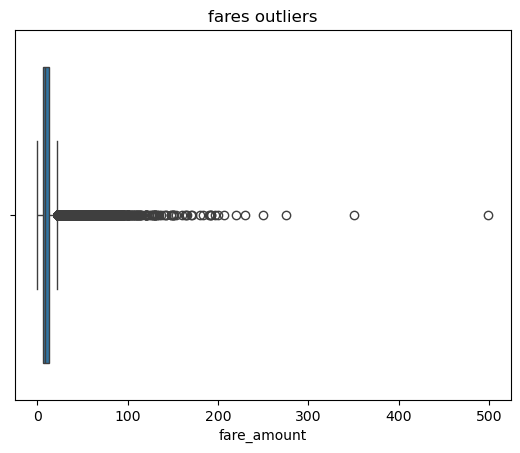

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df["fare_amount"])
plt.title("fares outliers")

Text(0.5, 1.0, 'fares outliers')

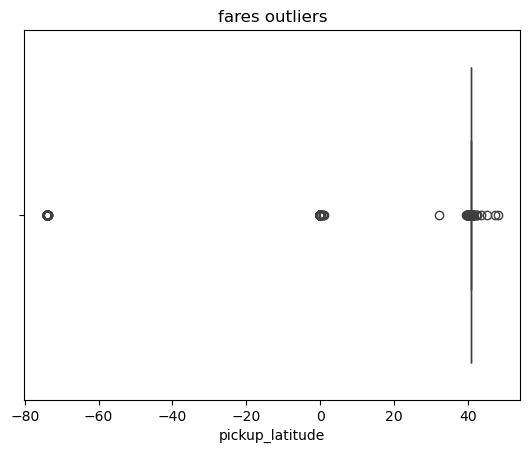

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df["pickup_latitude"])
plt.title("fares outliers")

Text(0.5, 1.0, 'fares outliers')

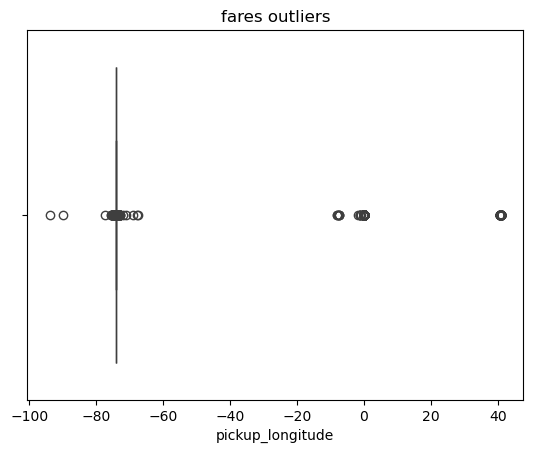

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df["pickup_longitude"])
plt.title("fares outliers")

Text(0.5, 1.0, 'fares outliers')

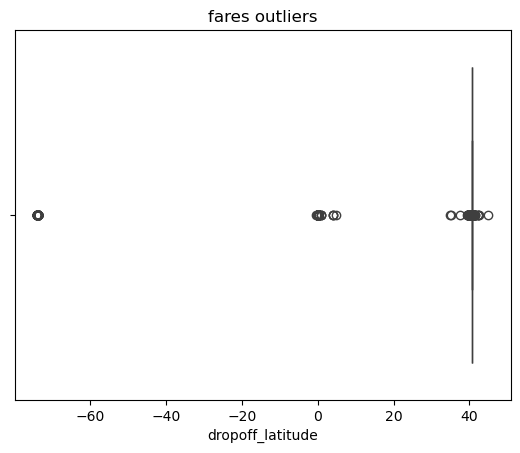

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df["dropoff_latitude"])
plt.title("fares outliers")

Text(0.5, 1.0, 'fares outliers')

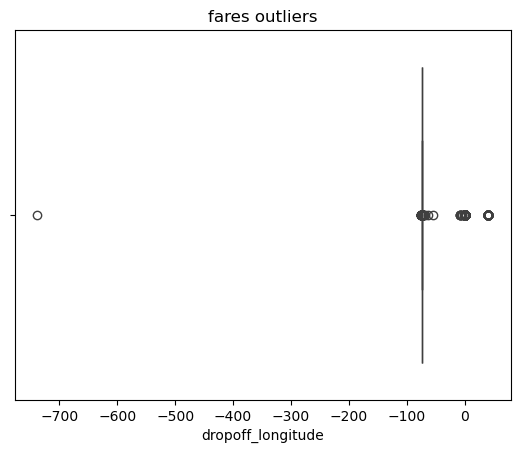

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df["dropoff_longitude"])
plt.title("fares outliers")

In [19]:
def remove_outliers(df, feature):
    q1= df[feature].quantile(0.25)
    q3= df[feature].quantile(0.75)
    iqr= q3- q1
    lower_bound= q1- (1.5* iqr)
    upper_bound= q3+ (1.5*iqr)
    df = df[(df[feature]>=lower_bound) & (df[feature]<=upper_bound)]
    return df

In [20]:
feat= ["fare_amount", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude"]
for f in feat:
    df= remove_outliers(df, f)

Text(0.5, 1.0, 'fares outliers')

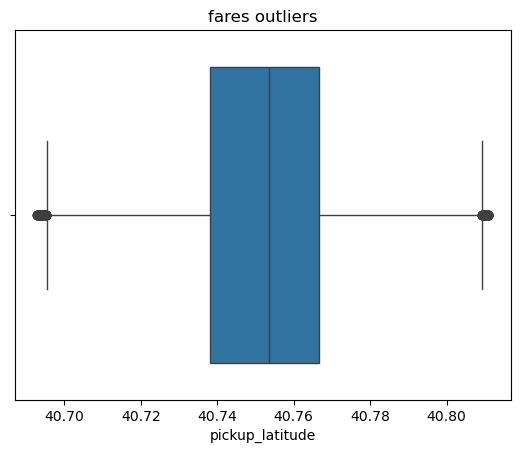

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df["pickup_latitude"])
plt.title("fares outliers")

In [22]:
def euclidean_distance(lat1, lon1, lat2, lon2):
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    distance = math.sqrt(dlat**2 + dlon**2)

    return distance

In [23]:
import math
distance = []

for i in range(len(df)):
    d = euclidean_distance(
        df['pickup_latitude'].iloc[i],
        df['pickup_longitude'].iloc[i],
        df['dropoff_latitude'].iloc[i],
        df['dropoff_longitude'].iloc[i]
    )

    distance.append(d)

df['distance'] = distance

In [24]:
df.drop([
    'pickup_latitude',
    'pickup_longitude',
    'dropoff_latitude',
    'dropoff_longitude'
], axis=1, inplace=True)

In [25]:
df.head()

,fare_amount,pickup_datetime,passenger_count,distance
0,7.5,2015-05-07 19:52:06 UTC,1,0.015140
1,7.7,2009-07-17 20:04:56 UTC,1,0.022103
2,12.9,2009-08-24 21:45:00 UTC,1,0.053109
3,5.3,2009-06-26 08:22:21 UTC,3,0.016528
5,4.9,2011-02-12 02:27:09 UTC,1,0.000000


In [26]:
df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime'],
    utc=True
)
df['hour'] = df['pickup_datetime'].dt.hour

In [27]:
df.drop('pickup_datetime', axis=1, inplace=True)

In [28]:
df.head()

,fare_amount,passenger_count,distance,hour
0,7.5,1,0.015140,19
1,7.7,1,0.022103,20
2,12.9,1,0.053109,21
3,5.3,3,0.016528,8
5,4.9,1,0.000000,2


In [29]:
print(df.isnull().sum())

fare_amount        0
passenger_count    0
distance           0
hour               0
dtype: int64


In [30]:
corr = df.corr(method='pearson', numeric_only=True)
print(corr)

                 fare_amount  passenger_count  distance      hour
fare_amount         1.000000         0.015807  0.809592  0.006286
passenger_count     0.015807         1.000000  0.003827  0.015072
distance            0.809592         0.003827  1.000000 -0.017673
hour                0.006286         0.015072 -0.017673  1.000000


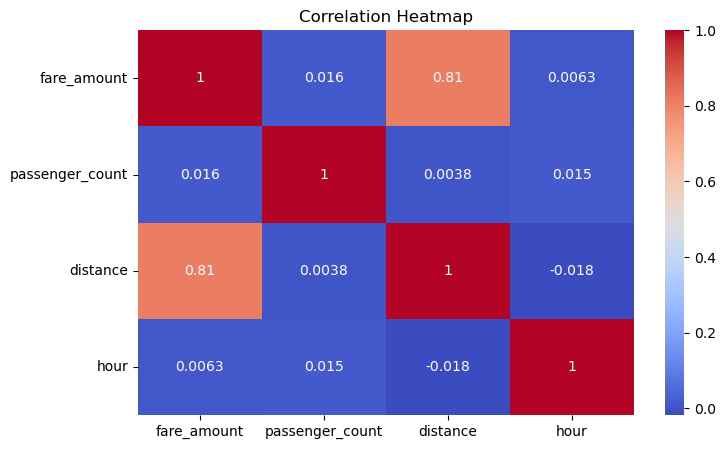

In [31]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    
)

plt.title('Correlation Heatmap')
plt.show()

In [32]:
#split dataset into X and y
X = df.drop('fare_amount', axis=1)

y = df['fare_amount']

In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y, 
    test_size=0.2,
    random_state=42
)

In [34]:
from sklearn.preprocessing import StandardScaler

scaler= StandardScaler()

X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [35]:
from sklearn.linear_model import LinearRegression
lr_model= LinearRegression()
lr_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.04,3.14,0.08]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.644
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[369.27,366. ,360.77]"


In [36]:
y_pred_lr= lr_model.predict(X_test_scaled)

In [37]:
print(y_pred_lr)

[13.30478238  7.03830785  8.36337617 ... 17.85384647 12.75785657
  8.67894446]


In [38]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42,
)

rf_model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

In [39]:
y_pred_rf = rf_model.predict(X_test)

In [40]:
import numpy as np
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# Linear Regression
r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

# Random Forest
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

In [41]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [r2_lr, r2_rf],
    'MAE': [mae_lr, mae_rf],
    'RMSE': [rmse_lr, rmse_rf]
})

print(results)

               Model  R2 Score       MAE      RMSE
0  Linear Regression  0.654946  1.633904  2.276127
1      Random Forest  0.676585  1.578374  2.203600
